# Chapitre 8 - Exercices 8.1 à 8.6

Ces exercices portent sur la **curation** des données (cours 1) et sur l'**augmentation**
traditionnelle (cours 2) :

- **8.1** : combien d'exemples acheter ? Extrapoler une courbe d'apprentissage sous
  contrainte de budget (calcul) ;
- **8.2** : le kappa de Cohen à la main, et le paradoxe de la prévalence (calcul) ;
- **8.3** : kappa de Fleiss, vote majoritaire et annotateur défaillant (mini-lab) ;
- **8.4** : un peu de données propres ou beaucoup de données bruitées ? (raisonnement et
  mini-lab) ;
- **8.5** : trouver le bon mélange de données, à la manière de Meta (mini-lab) ;
- **8.6** : augmentation contrefactuelle de genre et ses pièges (mini-lab et
  raisonnement).

Tous les exercices tournent sur CPU en quelques secondes.

In [1]:
import warnings
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVC

from aie import ch08_donnees as d8
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
rng = np.random.default_rng(0)


def log_lisible(ax, axes="y"):
    """Graduations log au format décimal simple (sans exposants mathtext)."""
    from matplotlib.ticker import FuncFormatter, NullFormatter
    for a in axes:
        axis = ax.yaxis if a == "y" else ax.xaxis
        axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        axis.set_minor_formatter(NullFormatter())

## Exercice 8.1 : Combien d'exemples acheter ?

**Énoncé.** Une équipe affine un modèle de classification de tickets de support. Elle
dispose de 2 000 exemples annotés et a entraîné le modèle sur des sous-ensembles :

| exemples | 250 | 500 | 1 000 | 1 500 | 2 000 |
|---|---|---|---|---|---|
| exactitude | 0,642 | 0,700 | 0,745 | 0,766 | 0,778 |

Il reste 10 000 dollars de budget. Annoter un exemple coûte 2 dollars.

1. Ajuster une loi $\mathrm{err}(n) = a n^{-b} + c$ et interpréter $c$.
2. Quelle exactitude prévoir si l'on dépense tout le budget en annotation ?
3. Combien rapporte (en points d'exactitude) le dernier millier de dollars, comparé au
   premier ?
4. La direction exige 0,85. Est-ce atteignable par l'annotation seule ?
5. Quelle est l'incertitude de ces prévisions si chaque mesure est bruitée de
   $\pm 0{,}005$ ?

**Rappels.** Cours 1, section 5 (section *Data Quantity* du livre) : on trace la
performance sur des sous-ensembles (25, 50, 100 %) pour estimer le gain de données
supplémentaires ; les rendements sont décroissants. Inverser la loi donne
$n^\star = \big(a / (e^\star - c)\big)^{1/b}$ pour une erreur cible $e^\star > c$.

**Solution.**

1. On ajuste les trois paramètres par moindres carrés (`fit_power_law`). $c$ est
   l'erreur **irréductible** : celle qui resterait avec une infinité d'exemples du même
   type (ambiguïté de la tâche, bruit d'étiquetage, limites du modèle).
2. 10 000 dollars à 2 dollars l'exemple : 5 000 exemples de plus, soit $n = 7\,000$. On
   évalue $1 - \mathrm{err}(7\,000)$.
3. Le premier millier de dollars fait passer de 2 000 à 2 500 exemples, le dernier de
   6 500 à 7 000. On compare $\mathrm{err}(2\,000) - \mathrm{err}(2\,500)$ et
   $\mathrm{err}(6\,500) - \mathrm{err}(7\,000)$.
4. Si $1 - c < 0{,}85$, la cible est **au-delà du plafond** : aucune quantité d'exemples
   du même type ne l'atteindra. Sinon, $n^\star = \big(a/(0{,}15 - c)\big)^{1/b}$ donne le
   nombre d'exemples, à comparer au budget.

In [2]:
n_obs = np.array([250, 500, 1000, 1500, 2000])
acc_obs = np.array([0.642, 0.700, 0.745, 0.766, 0.778])
a, b, c = d8.fit_power_law(n_obs, 1 - acc_obs)
acc = lambda n: 1 - d8.power_law(n, a, b, c)
print(f"a = {a:.2f}, b = {b:.3f}, c = {c:.3f}  ->  plafond 1 - c = {1 - c:.3f}")
print(f"Exactitude prévue à 7 000 exemples : {acc(7000):.3f} (gain : +{(acc(7000) - acc(2000)) * 100:.1f} pts)")
g1, g2 = acc(2500) - acc(2000), acc(7000) - acc(6500)
print(f"Premier millier de dollars : +{g1 * 100:.2f} pts ; dernier : +{g2 * 100:.2f} pts (rapport {g1 / g2:.1f})")
cible = 0.85
if 1 - c > cible:
    print(f"0,85 atteignable avec n* = {(a / (1 - cible - c)) ** (1 / b):,.0f} exemples")
else:
    print(f"0,85 est au-delà du plafond {1 - c:.3f} : inatteignable par l'annotation seule")

a = 2.19, b = 0.399, c = 0.116  ->  plafond 1 - c = 0.884
Exactitude prévue à 7 000 exemples : 0.820 (gain : +4.2 pts)
Premier millier de dollars : +0.90 pts ; dernier : +0.19 pts (rapport 4.7)
0,85 atteignable avec n* = 33,972 exemples


**Question 5 : incertitude.** On rejoue l'ajustement 500 fois en perturbant chaque
mesure d'un bruit uniforme de $\pm 0{,}005$ (un « bootstrap paramétrique »), et l'on
regarde la dispersion des prévisions.

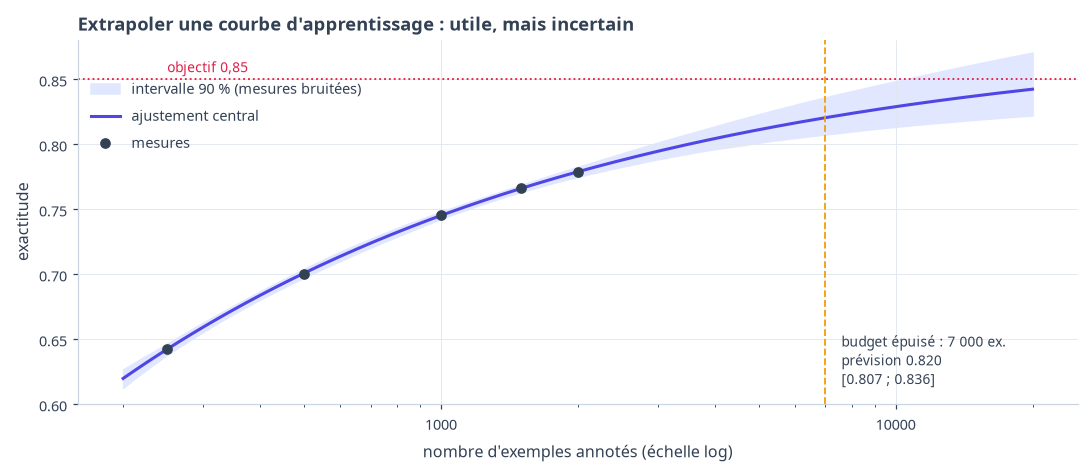

Plafond 1 - c : médiane 0.885, intervalle 90 % [0.841 ; 0.996]


In [3]:
grille = np.logspace(np.log10(200), np.log10(20000), 200)
preds, plafonds = [], []
for _ in range(500):
    try:
        aa, bb, cc = d8.fit_power_law(n_obs, 1 - (acc_obs + rng.uniform(-0.005, 0.005, len(n_obs))))
    except RuntimeError:
        continue
    preds.append(1 - d8.power_law(grille, aa, bb, cc))
    plafonds.append(1 - cc)
preds = np.array(preds)
lo, hi = np.percentile(preds, [5, 95], axis=0)
i7 = np.argmin(np.abs(grille - 7000))

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.fill_between(grille, lo, hi, color=LIGHT[INDIGO], label="intervalle 90 % (mesures bruitées)")
ax.plot(grille, acc(grille), color=INDIGO, label="ajustement central")
ax.plot(n_obs, acc_obs, "o", color=SLATE, label="mesures")
ax.axvline(7000, color=AMBER, ls="--", lw=1.2)
ax.text(7600, 0.615, f"budget épuisé : 7 000 ex.\nprévision {acc(7000):.3f}\n[{lo[i7]:.3f} ; {hi[i7]:.3f}]",
        fontsize=9, color=SLATE)
ax.axhline(cible, color=ROSE, ls=":", lw=1.2)
ax.text(250, cible + 0.005, "objectif 0,85", color=ROSE, fontsize=9)
ax.set_xscale("log")
log_lisible(ax, "x")
ax.set_ylim(0.6, 0.88)
ax.set_xlabel("nombre d'exemples annotés (échelle log)")
ax.set_ylabel("exactitude")
ax.set_title("Extrapoler une courbe d'apprentissage : utile, mais incertain")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.93))
finish(fig)
plt.show()
print(f"Plafond 1 - c : médiane {np.median(plafonds):.3f}, intervalle 90 % "
      f"[{np.percentile(plafonds, 5):.3f} ; {np.percentile(plafonds, 95):.3f}]")

**Vérification et interprétation.** Le gain prévu en dépensant tout le budget est
modeste (quelques points), et le dernier millier de dollars rapporte plusieurs fois
moins que le premier : ce sont les rendements décroissants. L'objectif de 0,85 est sous
le plafond estimé, donc atteignable en théorie, mais il demanderait de l'ordre de
34 000 exemples, soit près de 70 000 dollars : environ sept fois le budget. Et
l'incertitude est énorme : l'intervalle à 90 % du plafond va d'environ 0,84 (objectif
inatteignable) à presque 1. Avec cinq points tous situés avant 2 000 exemples, une
extrapolation d'un facteur 3,5 (et a fortiori 17) doit être présentée avec sa
fourchette. Recommandation : dépenser une partie du budget, remesurer la courbe, et
investir en parallèle dans ce qui réduit $c$ (consignes, nettoyage des étiquettes,
couverture des cas manquants, meilleur modèle de base).

> **À retenir.** La courbe d'apprentissage transforme une question de budget en calcul,
> mais extrapoler loin est incertain. Si l'objectif dépasse le plafond $1-c$, acheter des
> exemples du même type ne sert à rien : il faut changer la nature des données ou le
> modèle.

## Exercice 8.2 : Le kappa de Cohen à la main, et le paradoxe de la prévalence

**Énoncé.** Deux modérateurs, A et B, étiquettent 100 messages comme « ok » ou
« toxique » :

| | B : ok | B : toxique |
|---|---|---|
| **A : ok** | 85 | 6 |
| **A : toxique** | 5 | 4 |

1. Calculer l'accord brut $p_o$, l'accord attendu par hasard $p_e$ et le kappa de Cohen.
2. Deux annotateurs **indépendants** ont chacun une exactitude $q = 0{,}95$ sur une tâche
   binaire où la classe positive a une prévalence $\pi$. Exprimer $p_o$, $p_e$ et
   $\kappa$ en fonction de $q$ et $\pi$, puis tracer $\kappa(\pi)$.
3. Expliquer pourquoi deux équipes d'annotateurs aussi compétentes peuvent obtenir des
   kappas très différents.

**Rappels.** Cours 1, section 6 : $\kappa = (p_o - p_e)/(1 - p_e)$ avec
$p_e = \sum_j p_A(j) p_B(j)$. Le kappa corrige l'accord brut de la part due au hasard.

**Solution.**

1. $p_o = (85 + 4)/100 = 0{,}89$. Marges : A dit « ok » 91 fois, B 90 fois. Donc
   $p_e = 0{,}91 \times 0{,}90 + 0{,}09 \times 0{,}10 = 0{,}819 + 0{,}009 = 0{,}828$ et
   $$\kappa = \frac{0{,}89 - 0{,}828}{1 - 0{,}828} = \frac{0{,}062}{0{,}172} \approx 0{,}36.$$
   Un accord brut de 89 % ne correspond qu'à un accord « passable ».
2. Chaque annotateur a raison avec probabilité $q$, indépendamment. Ils sont d'accord
   s'ils ont tous deux raison ou tous deux tort : $p_o = q^2 + (1-q)^2$, **indépendant de
   $\pi$**. Chacun dit « positif » avec probabilité $m = \pi q + (1-\pi)(1-q)$, donc
   $p_e = m^2 + (1-m)^2$, et $\kappa = (p_o - p_e)/(1 - p_e)$.
   Quand $\pi \to 0$, $m \to 1 - q$ et $p_e \to q^2 + (1-q)^2 = p_o$ : le kappa tend
   vers 0, bien que les annotateurs soient tout aussi compétents.

kappa (module) = 0.3605  ; calcul à la main = 0.3605


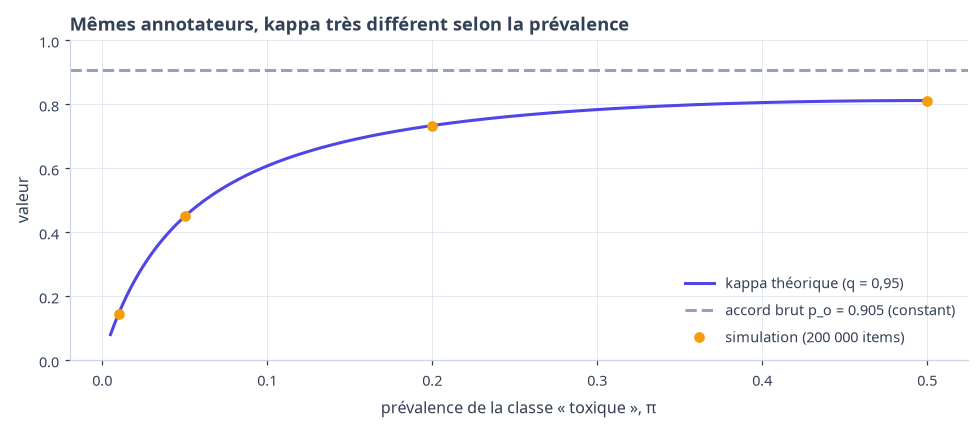

In [4]:
A = ["ok"] * 85 + ["ok"] * 6 + ["toxique"] * 5 + ["toxique"] * 4
B = ["ok"] * 85 + ["toxique"] * 6 + ["ok"] * 5 + ["toxique"] * 4
print(f"kappa (module) = {d8.cohen_kappa(A, B):.4f}  ; calcul à la main = {0.062 / 0.172:.4f}")

q = 0.95
pi = np.linspace(0.005, 0.5, 200)
po = q ** 2 + (1 - q) ** 2
m = pi * q + (1 - pi) * (1 - q)
pe = m ** 2 + (1 - m) ** 2
kappa = (po - pe) / (1 - pe)
# vérification par simulation pour quelques prévalences
sim = []
for p_ in [0.01, 0.05, 0.2, 0.5]:
    y = (rng.random(200_000) < p_).astype(int)
    a1 = np.where(rng.random(len(y)) < q, y, 1 - y)
    a2 = np.where(rng.random(len(y)) < q, y, 1 - y)
    sim.append((p_, d8.cohen_kappa(a1, a2)))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pi, kappa, color=INDIGO, label="kappa théorique (q = 0,95)")
ax.axhline(po, color=GRAY, ls="--", label=f"accord brut p_o = {po:.3f} (constant)")
ax.plot(*zip(*sim), "o", color=AMBER, label="simulation (200 000 items)")
ax.set_xlabel("prévalence de la classe « toxique », π")
ax.set_ylabel("valeur")
ax.set_ylim(0, 1)
ax.set_title("Mêmes annotateurs, kappa très différent selon la prévalence")
ax.legend(loc="lower right")
finish(fig)
plt.show()

**Vérification.** Le module retrouve 0,36. La simulation colle à la courbe théorique : à
compétence égale ($q = 0{,}95$), le kappa vaut environ 0,8 pour des classes équilibrées
et s'effondre quand la classe positive devient rare.

3. C'est le **paradoxe du kappa** : à classes rares, $p_e$ est proche de $p_o$, et la
   moindre erreur pèse lourd. Comparer les kappas de deux projets n'a de sens qu'à
   prévalence comparable ; il faut rapporter aussi la prévalence, et éventuellement
   l'accord par classe (accord positif, accord négatif) ou équilibrer l'échantillon
   d'items soumis à la double annotation.

> **À retenir.** Le kappa corrige l'accord brut du hasard, mais dépend de la
> prévalence : $p_o = q^2+(1-q)^2$ ne bouge pas quand les classes se déséquilibrent,
> alors que $p_e$ monte. Rapportez toujours le kappa avec la distribution des classes.

## Exercice 8.3 : Fleiss, vote majoritaire et annotateur défaillant

**Énoncé.** Six annotateurs étiquettent 400 réponses d'assistant en trois catégories
(« utile », « partiellement utile », « inutile »). Quatre sont sérieux (exactitude
0,85), un a mal compris la consigne et classe trop souvent en « inutile », et un
« spammeur » répond au hasard pour aller vite.

1. Calculer le kappa de Fleiss des six.
2. Identifier les annotateurs problématiques **sans connaître la vérité**, par deux
   méthodes : le kappa de Fleiss en retirant chaque annotateur à tour de rôle, et le
   kappa de Cohen de chaque annotateur contre le vote majoritaire des autres.
3. Pour une tâche binaire et des annotateurs indépendants d'exactitude $p$, calculer la
   probabilité que le vote majoritaire de 3 (puis de 5) annotateurs soit juste. Combien
   d'annotateurs par item faut-il ?

**Rappels.** Cours 1, section 6 : kappa de Fleiss
$\kappa_F = (\bar P - P_e)/(1 - P_e)$ ; la section *Inspect Data* du livre recommande
de tracer les annotations par annotateur et de calculer le désaccord inter-annotateurs.

**Solution (questions 1 et 2).** On simule les annotations avec `simulate_annotators`
(le spammeur a une exactitude de 1/3, soit le hasard pour trois classes), puis on
calcule les deux diagnostics.

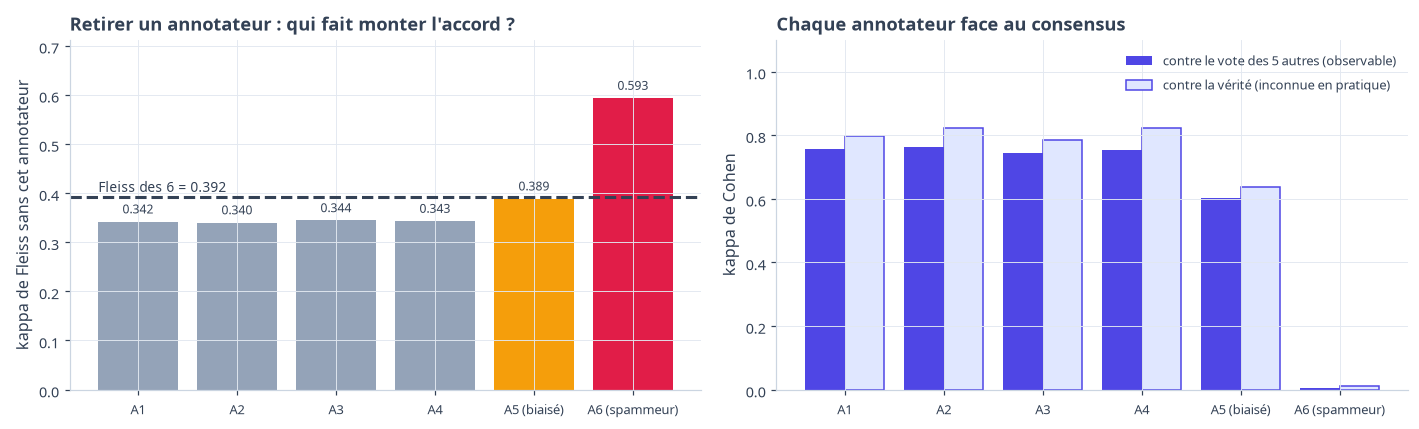

In [5]:
vrai = rng.integers(0, 3, 400)
noms = ["A1", "A2", "A3", "A4", "A5 (biaisé)", "A6 (spammeur)"]
R = d8.simulate_annotators(vrai, [0.85, 0.85, 0.85, 0.85, 0.6, 1 / 3], 3, seed=11,
                           bias=[None, None, None, None, 2, None])
kF = d8.fleiss_kappa(d8.ratings_to_counts(R, 3))
loo = [d8.fleiss_kappa(d8.ratings_to_counts(np.delete(R, j, axis=1), 3)) for j in range(6)]


def vote(M):
    """Vote majoritaire ligne par ligne (égalité : plus petite catégorie)."""
    return np.array([np.bincount(r, minlength=3).argmax() for r in M])


k_vs_maj = [d8.cohen_kappa(R[:, j], vote(np.delete(R, j, axis=1)), labels=range(3)) for j in range(6)]
k_vs_vrai = [d8.cohen_kappa(R[:, j], vrai, labels=range(3)) for j in range(6)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.bar(noms, loo, color=[GRAY] * 4 + [AMBER, ROSE])
ax.axhline(kF, color=SLATE, ls="--")
ax.text(-0.4, kF + 0.01, f"Fleiss des 6 = {kF:.3f}", fontsize=9)
annotate_bars(ax, "{:.3f}", fontsize=8)
ax.set_ylim(0, max(loo) * 1.2)
ax.set_ylabel("kappa de Fleiss sans cet annotateur")
ax.set_title("Retirer un annotateur : qui fait monter l'accord ?")
plt.setp(ax.get_xticklabels(), fontsize=8.5)
ax = axes[1]
xs = np.arange(6)
ax.bar(xs - 0.2, k_vs_maj, 0.4, color=INDIGO, label="contre le vote des 5 autres (observable)")
ax.bar(xs + 0.2, k_vs_vrai, 0.4, color=LIGHT[INDIGO], edgecolor=INDIGO, label="contre la vérité (inconnue en pratique)")
ax.set_xticks(xs, noms, fontsize=8.5)
ax.set_ylim(0, 1.1)
ax.set_ylabel("kappa de Cohen")
ax.set_title("Chaque annotateur face au consensus")
ax.legend(loc="upper right", fontsize=8.5)
finish(fig)
plt.show()

**Vérification.** Retirer le spammeur fait nettement monter le kappa de Fleiss. Retirer
l'annotateur biaisé le laisse presque inchangé, alors que retirer un annotateur sérieux
le fait baisser franchement : relativement aux autres, A5 apporte peu d'accord, ce qui
le rend suspect (il est moins bon que les sérieux, mais meilleur que le hasard). Le kappa contre le vote majoritaire des autres classe les annotateurs presque
exactement comme le kappa contre la vérité, que l'on ne connaît pas en pratique : le
**consensus** sert d'étalon. (Ce diagnostic suppose que la majorité est sérieuse ; si
la consigne est mal comprise par tous, le consensus se trompe aussi.)

**Solution (question 3).** Avec $m$ annotateurs indépendants d'exactitude $p$ (binaire),
le vote est juste si au moins $\lceil m/2 \rceil$ ont raison :
$$P_3 = p^3 + 3p^2(1-p), \qquad P_5 = \sum_{k=3}^{5} \binom{5}{k} p^k (1-p)^{5-k}.$$
Pour $p = 0{,}8$ : $P_3 = 0{,}512 + 0{,}384 = 0{,}896$ et $P_5 \approx 0{,}942$.

p = 0,8 : P1 = 0.800, P3 = 0.896, P5 = 0.942, P7 = 0.967


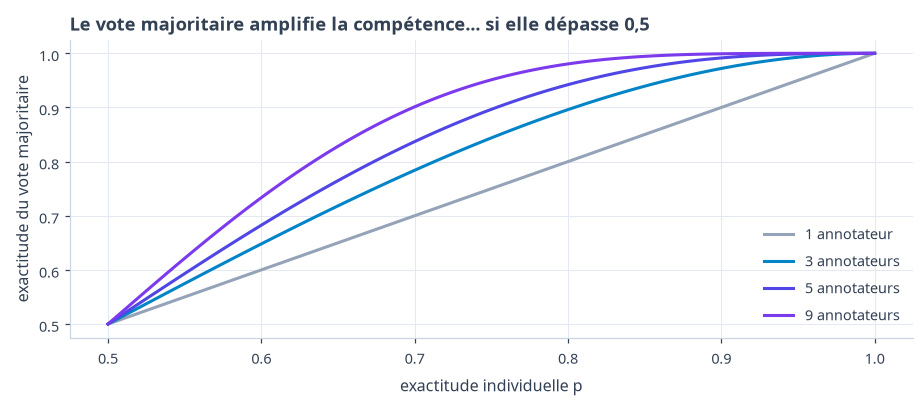

In [6]:
from math import comb

ps = np.linspace(0.5, 1, 101)
maj = lambda p, m: sum(comb(m, k) * p ** k * (1 - p) ** (m - k) for k in range(m // 2 + 1, m + 1))
print(f"p = 0,8 : P1 = 0.800, P3 = {maj(0.8, 3):.3f}, P5 = {maj(0.8, 5):.3f}, P7 = {maj(0.8, 7):.3f}")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for m_, c_ in zip([1, 3, 5, 9], [GRAY, SKY, INDIGO, VIOLET]):
    ax.plot(ps, [maj(p, m_) for p in ps], color=c_, label=f"{m_} annotateur{'s' if m_ > 1 else ''}")
ax.set_xlabel("exactitude individuelle p")
ax.set_ylabel("exactitude du vote majoritaire")
ax.set_title("Le vote majoritaire amplifie la compétence... si elle dépasse 0,5")
ax.legend(loc="lower right")
finish(fig)
plt.show()

Passer de 1 à 3 annotateurs apporte le gros du gain ; de 3 à 5, le gain est plus faible
pour un coût qui augmente de deux tiers. En pratique, on fait souvent annoter **tous**
les items par un annotateur et un **échantillon** par trois, pour mesurer l'accord et
détecter les annotateurs défaillants. Les erreurs **corrélées** (consigne ambiguë pour
tout le monde) ne se corrigent pas par le vote : c'est la consigne qu'il faut réécrire.

> **À retenir.** Le kappa de Fleiss mesure l'accord global ; le retrait d'un annotateur
> à la fois et le kappa contre le consensus identifient les annotateurs défaillants sans
> vérité terrain. Le vote majoritaire améliore l'exactitude si les erreurs sont
> indépendantes et les annotateurs meilleurs que le hasard.